In [1]:
# A decision tree uses a tree structure to represent a number of possible desicion paths and an outcome for each path.
# A DT is ML algorithm that makes predictions by asking a sequence of questions about the input data.

# GINI IMPURITY
#              k
# - Gini = 1 - ∑pi^2
#              i=1
# - where k = number of classes; pi = proportion of observations belonging to class i
# - Example;
# - 5 red and 5 blue
# - Gini = 1 - (0.5^2 + 0.5^2) = 0.5
# - 10 reds and 0 blue
# - Gini = 1 - (1^2 + 0^2) = 0
#
# - Group                       Gini Impurity
#   5 red, 5 blue               0.5
#   8 red, 2 blue               0.32
#   10 red, 0 blue              0
#
# - The lower the Gini Impurity, the purer the group.
#
# > Which question is best?
#
# - Suppose we have 8 observations, 5 people play football and 3 people don't
# - Before splitting the dataset, its Gini impurity is Gini(parent) = 1 - (5/8)^2 - (3/8)^2 = 0.469
# - If we split data using the question: Is it raining?
# - Yes > 0 play, 3 don't play ; Gini = 0
# - No  > 5 play, 0 don't play ; Gini = 0
# - Result: Perfect split
# - Both groups contain only one class. The resulting weighted Gini impurity is zero.
#
# - The model measures how much impurity was reduced by splitting. This is called Gini Gain: 
# - GiniGain = Gini(parent) - Gini(children)
#
# - Weighted impurity of the children.
#                r
# - Gini_split = ∑(nj/n)Gini(j)
#                j=1
# - Then: GiniGain = Gini(parent) - Gini_split
#
# - In our exmaple: GiniGain = 0.469 - 0 = 0.469
# - The model tries different possible questions and selects the one that produces the greatest impurity reduction

# ENTROPY

# - Its another way to measure impurity
# - a set S of data, each member of which is labelled as belonging to one of a finite number of classes C_1, ..., C_n
# - p_i is the proportion of data labelled as class c_i
#         k
# H(S) = -∑(p_i(log_2(p_i)))
#         i=1
#
# - (Standard) convetion that 0 log 0 = 0
# - each term -P_i log_2 p_i is non-negative and is close to 0 precisely when p_i is either close to 0 or close to 1
# - this means the entropy will be small when every p_i is close to 0 or 1 (i.e when most of the data is in a single class)
# - and it will be larger when many of the p_i's are not close to 0 (i.e, when the data is spread across multiple classes). What we desire.
#
# - Entropy measures uncertainity;
# - Entropy = 0 means perfectly pure
# - Higher entropy means more uncertainity
# - For two equally represented classes, entropy = 1 bit
#
# - Using entropy, the reduction in uncertainity is called 'Information Gain'
#   IG = H(parent) - H(children)

# - Hence we have 2 common approaches:
#   Method               Measures            Split selection
#-------------------------------------------------------------
#   Gini                 Impurity           Highest Gini reduction
#   Entropy              Uncertainity       Highest information gain
#
# > What happens after the first question?
# 
# - The algorithm doesn't necessarily stop after one split
# - It repeats the process on the resulting groups
# - This is called recursive splitting
# - The algorithm continues asking questions until it reaches a stopping condition.
#
# - Some possible stopping conditions include:
#   1. All observations in a group belong to the same class
#   2. The tree reaches its maximum depth
#   3. There are too few observations to split further
#   4. Further splitting doesn't produce enough improvement
#
# - This is how a DT builds its structure

# - For numerical features such as temp, age, solary e.t.c, the algo. might discovers where splitting the dataset gives a perfect separation.
# - In this dataset, algo. might discover that splitting the age 27.5 gives a perfect separation
#
# Person	Age	Buys product?
# A	        18	No
# B	        22	No
# C	        25	No
# D	        30	Yes
# E	        35	Yes
# F	        40	Yes
#
# - it's rules becomes:
# Age <= 27.5 (No)
# Age > 27.5 (Yes)
#
# This is important as the algorithm automatically searches for thresholds.
# You don't need to manually tell it that 27.5 is the best dividing point.

# Biggest Problem: Overfitting
# - When model achieves 100% accuracy on the training data but when you give it new data it has never seen before, its predictions might be terrible.
# How to prevent this?
# - We used techniques called regularization and pruning.
# - Some important parameters in SciKit-learn:
#
# Parameter	        What it controls
#---------------------------------------------------------
# max_depth	        Maximum depth of the tree
# min_samples_split	Minimum samples needed to split a node
# min_samples_leaf	Minimum samples required in a leaf
# max_leaf_nodes	Maximum number of leaf nodes
#
# These parameters prevent the tree from becoming unnecessarily complex.
#
# - We don't require feature scaling in DT, hence no need to normalize these features before training.
# - Beacuse the tree makes decisions using thresholds rather than calculating distances or relying on the numerical scale of features.
#

# >>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>

# 

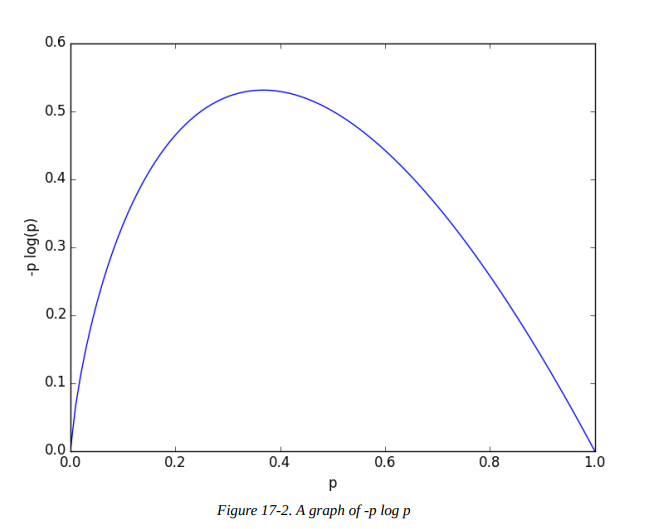

In [2]:
# ENTROPY

from typing import List
import math

#         k
# H(S) = -∑(p_i(log_2(p_i)))
#         i=1
def entropy(class_probabilities: List[float]) -> float:
    """Given a list of class probabilities, compute the entropy"""
    return sum(-p * math.log(p, 2)
               for p in class_probabilities
               if p > 0)                        # ignore zero probabilities

assert entropy([1.0]) == 0
assert entropy([0.5, 0.5]) == 1
assert 0.81 < entropy([0.25, 0.75]) < 0.82

# Our data will consist of pairs(input, label), which means that we'll need to compute the class probabilities ourselves

In [3]:
from typing import Any
from collections import Counter

def class_probabilities(labels: List[Any]) -> List[float]:
    total_count = len(labels)
    return [count / total_count
            for count in Counter(labels).values()]

def data_entropy(labels: List[Any]) -> float:
    return entropy(class_probabilities(labels))

assert data_entropy(['a']) == 0
assert data_entropy([True, False]) == 1
assert data_entropy([3, 4, 4, 4]) == entropy([0.25, 0.75])

labels = [3, 4, 4, 4]
print(class_probabilities(labels))
print(data_entropy(labels))

[0.25, 0.75]
0.8112781244591328


In [4]:
counter = Counter([3, 4, 4, 4])
print(counter)
print(f"Keys    : {counter.keys()}")
print(f"Values  : {counter.values()}")

Counter({4: 3, 3: 1})
Keys    : dict_keys([3, 4])
Values  : dict_values([1, 3])


In [5]:
# Entropy measures how mixed or impure a group of data is
# Low entropy - data mostly made up of one class, low uncertainity
# High entropy - data is very mixed, lots of uncertainity.

In [6]:
# THE ENTROPY OF A PARTITION

# - Partitioning of a set of data
# - A partition should have low entropy if it splits the data into subsets that themselves have low entropy (i.e., are highly certain)
#
# - If we partition our data S into subsets S_1, ..., S_n containing proportions q_1, ..., q_n of the data, then we compute the entropy of the partition as a weighted sum
# H = q_1H(S_1) + ... + q_nH(S_n)
# 
# which can be implemented as:

def partition_entropy(subsets: List[List[Any]]) -> float:
    """Returns the entropy from this partition of data into subsets"""
    total_count = sum(len(subset) for subset in subsets)
    return sum(data_entropy(subset) * len(subset) / total_count
               for subset in subsets)

# NOTE:
# One problem with this approach is that partitioning by an attribute with many different values will result in a very low entropy due to overfitting. 
# For this reason, you should probably try to avoid (or bucket, if appropriate) attributes with large numbers of possible values when creating decision trees.


In [7]:
# Creating a decision tree

from typing import NamedTuple, Optional

class Candidate(NamedTuple):
    level: str
    lang: str
    tweets: bool
    phd: bool
    did_well: Optional[bool] = None # allow unlabelled data

inputs = [Candidate('Senior', 'Java', False, False, False),
Candidate('Senior', 'Java', False, True, False),
Candidate('Mid', 'Python', False, False, True),
Candidate('Junior', 'Python', False, False, True),
Candidate('Junior', 'R', True, False, True),
Candidate('Junior', 'R', True, True, False),
Candidate('Mid', 'R', True, True, True),
Candidate('Senior', 'Python', False, False, False),
Candidate('Senior', 'R', True, False, True),
Candidate('Junior', 'Python', True, False, True),
Candidate('Senior', 'Python', True, True, True),
Candidate('Mid', 'Python', False, True, True),
Candidate('Mid', 'Java', True, False, True),
Candidate('Junior', 'Python', False, True, False)
]



In [8]:
# Our tree will considt of 
# 0. Root node - where we start
# 1. Desicion nodes - which ask a question and direct us differently depending on the answer
# 2. Lead nodes - which give us the prediction
#
# Build using ID3 algorithm, that operates in the followinf manner
#
# 1. If the data all have the same label, create a leaf node that predicts that label and then stop
# 2. If the list of attributes is empty(i.e., there are no more possible questions to ask), create a leaf node that predicts the most commen label and stop
# 3. Otherwise try partitioning the data by each of the attributes.
# 4. Choose the 'partition with the lowest partition entropy'.
# 5. Add a decision node based on the chosen attribute.
# 6. Recur on each partitioned subest using the remaining attributes.

In [ ]:
# First step; Find partition with the least entropy

from typing import Dict, TypeVar
from collections import defaultdict # automayically creates a default value for a missing key

T = TypeVar('T') # generic type for inputs

# Partition function

def partition_by(inputs: List[T], attribute: str) -> Dict[Any, List[T]]:
    """Partition the inputs into lists based on the specified attribute."""
    partitions: Dict[Any, List[T]] = defaultdict(list)
    for input in inputs:
        key = getattr(input, attribute)     # value of the specified attribute
        partitions[key].append(input)       # add input to the correct partition
    return partitions

# Entropy compute function

def partition_entropy_by(inputs: List[Any],
                         attribute: str,
                         label_attribute: str) -> float:
    """Compute the entropy corresponding to the given partition"""
    
    # partitions consist of our inputs
    partitions = partition_by(inputs, attribute)

    # but partition_entropy needs just the class labels
    labels = [[getattr(input, label_attribute) for input in partition]
              for partition in partitions.values()]

    return partition_entropy(labels)


In [21]:
print('labels', partition_entropy_by(inputs, 'level', 'did_well'))

>>  [[False, False, False, True, True], [True, True, True, True], [True, True, False, True, False]]
labels 0.6935361388961919


In [18]:
for key in ['level','lang','tweets','phd']:
    print(f"{key}({partition_entropy_by(inputs, key, 'did_well'):.3f}): {partition_by(inputs, key)}")

level(0.694): defaultdict(<class 'list'>, {'Senior': [Candidate(level='Senior', lang='Java', tweets=False, phd=False, did_well=False), Candidate(level='Senior', lang='Java', tweets=False, phd=True, did_well=False), Candidate(level='Senior', lang='Python', tweets=False, phd=False, did_well=False), Candidate(level='Senior', lang='R', tweets=True, phd=False, did_well=True), Candidate(level='Senior', lang='Python', tweets=True, phd=True, did_well=True)], 'Mid': [Candidate(level='Mid', lang='Python', tweets=False, phd=False, did_well=True), Candidate(level='Mid', lang='R', tweets=True, phd=True, did_well=True), Candidate(level='Mid', lang='Python', tweets=False, phd=True, did_well=True), Candidate(level='Mid', lang='Java', tweets=True, phd=False, did_well=True)], 'Junior': [Candidate(level='Junior', lang='Python', tweets=False, phd=False, did_well=True), Candidate(level='Junior', lang='R', tweets=True, phd=False, did_well=True), Candidate(level='Junior', lang='R', tweets=True, phd=True, did

In [10]:
# Find the minimum-entropy partition for the whole dataset:

for key in ['level','lang','tweets','phd']:
    print(key, partition_entropy_by(inputs, key, 'did_well'))

assert 0.69 < partition_entropy_by(inputs, 'level', 'did_well') < 0.70
assert 0.86 < partition_entropy_by(inputs, 'lang', 'did_well') < 0.87
assert 0.78 < partition_entropy_by(inputs, 'tweets', 'did_well') < 0.79
assert 0.89 < partition_entropy_by(inputs, 'phd', 'did_well') < 0.90

# The lowest entropy comes from splitting on 'level', so we need to make a subtree for each possible 'level' value.
# Every 'Mid' candidate is labelled True, which means that the 'Mid' subtree is simply a leaf node predicting True.
# For 'Senior' candidates, we have a mix of Trues and Falses, so we need to split again:

senior_inputs = [input for input in inputs if input.level == 'Senior']

assert 0.4 == partition_entropy_by(senior_inputs, 'lang', 'did_well')
assert 0.0 == partition_entropy_by(senior_inputs, 'tweets', 'did_well')
assert 0.95 < partition_entropy_by(senior_inputs, 'phd', 'did_well') < 0.96

# This shows that our next split should be on tweets, which result in a zero-entropy partition. 
# For these 'Senior'-level candidates, "yes" tweets always result in True while "no" tweets always result in a False.
# Finally, if we do the same thing for the Junior candidates, we end up splitting on phd, after which we find that no PhD always results in True and PhD always results in False.

level 0.6935361388961919
lang 0.8601317128547441
tweets 0.7884504573082896
phd 0.8921589282623617


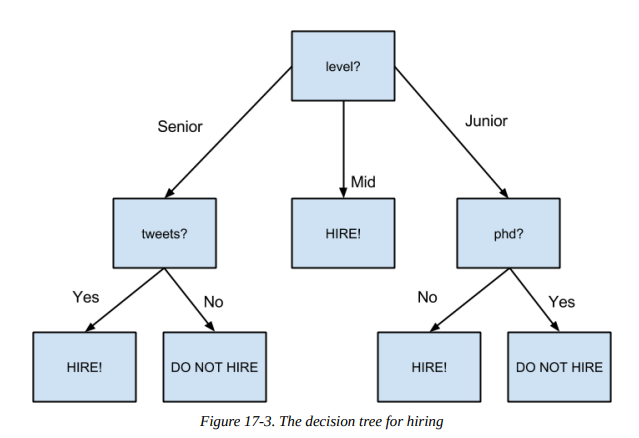

In [11]:
# Putting It All Together

# We define a 'tree' to be either:
# 1. a 'Leaf' (that predicts a single value), or
# 2. a 'Split' (Containing an attribute to split on, subtrees for specific values of that attribute, and possibly a default value to use if we see an unknown value)

from typing import NamedTuple, Union, Any

class Leaf(NamedTuple):
    value: Any

class Split(NamedTuple):
    attribute: str
    subtrees: dict
    default_value: Any = None

DecisionTree = Union[Leaf, Split]

In [12]:
# Our 'hiring' tree would look like:

hiring_tree = Split('level', {      # first, consider "level"
    'Junior': Split('phd', {        # if level is 'Junior', next look at "phd"
        False: Leaf(True),          #   if "phd" is False, predict True
        True: Leaf(False)           #   if "phd" is True, predict False
    }),
    'Mid': Leaf(True),              # if level is "Mid", just predict true
    'Senior': Split('tweets', {     # if level is 'Senior', look at "tweets"
        False: Leaf(False),         #   if "tweets" is False, predict False
        True: Leaf(True)            #   if "tweets" is True, predict True
    })
})

# What to do ifhiring tree encounters a candidate whose level is 'Intern'?
# Handled by populating the 'default_value' attribute with the most common label.

# Input classification

def classify(tree: DecisionTree, input: Any) -> Any:
    """Classify the input using the given decision tree"""

    # If this is a leaf node, return its value
    if isinstance(tree, Leaf):
        return tree.value

    # Otherwise this tree consists of an attribute to split on
    # and a dictionary whose keys are values of that attribute
    # and whose values are subtrees to consider next
    subtree_key = getattr(input, tree.attribute)
    if subtree_key not in tree.subtrees:    # If no subtree for key,
        return tree.default_value           # return the default value.

    subtree = tree.subtrees[subtree_key]    # Choose the appropriate subtree
    return classify(subtree, input)         # and use it to classify the input.

# Build tree representation from our training data

def build_tree_id3(inputs: List[Any],
                   split_attributes: List[str],
                   target_attribute: str) -> DecisionTree:
    # Count target labels
    label_counts = Counter(getattr(input, target_attribute)
                           for input in inputs)
    most_common_label = label_counts.most_common(1)[0][0]

    # If there's a unique label, predict it
    if len(label_counts) == 1:
        return Leaf(most_common_label)

    # If no split attributes left, return the majority label
    if not split_attributes:
        return Leaf(most_common_label)

    # Otherwise split by the best attribute

    def split_entropy(attribute: str) -> float:
        """Helper function for finding the best attribute"""
        return partition_entropy_by(inputs, attribute, target_attribute)

    best_attribute = min(split_attributes, key=split_entropy)

    partitions = partition_by(inputs, best_attribute)
    new_attributes = [a for a in split_attributes if a != best_attribute]

    # Recursively build the subtrees
    subtrees = {attribute_value: build_tree_id3(subset,
                                                new_attributes,
                                                target_attribute)
                for attribute_value, subset in partitions.items()} 

    return Split(best_attribute, subtrees, default_value=most_common_label)

In [13]:
# Apply new data to the tree

tree = build_tree_id3(inputs,
                      ['level', 'lang', 'tweets', 'phd'],
                      'did_well')

# Should predict True
assert classify(tree, Candidate("Junior", "Java", True, False))
# Should predict False
assert not classify(tree, Candidate("Junior", "Java", True, True))
# Should predict True
assert classify(tree, Candidate("Intern", "Java", True, True))

In [14]:
# RANDOM FORESTS

# - It's one way of avoiding overfitting in DT.
# - In random forest, we build multiple decision trees, and combine their outputs. 
# - If they are classification trees, we might let them vote; if they're regression trees, we might average their predictions.
#
# - How do we get random trees?
# - 1. Bootstraping data. This technique is known as bootstrap aggregating or bagging.
# - 2. Changing the way we choose the 'best_attribute' to split on.

In [15]:
# Gradient Boost